In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

PROJECT_DIR = Path.cwd().parent
DATA_FILE = PROJECT_DIR / "data" / "feature_engineered_dataset.csv"

model_df = pd.read_csv(DATA_FILE)

model_df["observed_at_ist"] = pd.to_datetime(
    model_df["observed_at_ist"]
)

model_df = model_df.sort_values(
    "observed_at_ist"
).reset_index(drop=True)

print("Dataset loaded successfully!")
print("Shape:", model_df.shape)
print("Stations:", model_df["candidate_station"].nunique())

display(model_df.head())

Dataset loaded successfully!
Shape: (197697, 59)
Stations: 13


,observed_at_ist,observed_at,location_id,station_name,candidate_station,region,latitude,longitude,co,no,...,month_cos,pm25_lag_1,pm25_lag_3,pm25_lag_6,pm25_lag_12,pm25_lag_24,pm25_rolling_mean_6h,pm25_rolling_mean_12h,pm25_rolling_mean_24h,pm25_rolling_std_24h
0,2025-02-19 01:00:00+05:30,2025-02-18 19:30:00+00:00,6932,"Alipur, Delhi - DPCC",Alipur,North Delhi,28.815329,77.153010,0.150,5.0,...,0.866025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025-02-19 01:00:00+05:30,2025-02-18 19:30:00+00:00,10486,"Mundka, Delhi - DPCC",Mundka,West Delhi,28.684678,77.076574,0.945,62.6,...,0.866025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2025-02-19 01:00:00+05:30,2025-02-18 19:30:00+00:00,50,"Punjabi Bagh, Delhi - DPCC",Punjabi Bagh,West Delhi,28.674045,77.131023,1.160,31.6,...,0.866025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2025-02-19 01:00:00+05:30,2025-02-18 19:30:00+00:00,6358,"Mandir Marg, New Delhi - DPCC",Mandir Marg,Central Delhi,28.636429,77.201067,1.990,98.0,...,0.866025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2025-02-19 01:00:00+05:30,2025-02-18 19:30:00+00:00,6356,"Pusa, Delhi - DPCC",Pusa,Central Delhi,28.639645,77.146262,0.970,138.0,...,0.866025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
# Get unique timestamps in chronological order
unique_times = np.sort(
    model_df["observed_at_ist"].dropna().unique()
)

# 80% chronological cutoff
split_index = int(len(unique_times) * 0.80)
split_time = unique_times[split_index]

# Split the dataset
train_df = model_df[
    model_df["observed_at_ist"] < split_time
].copy()

test_df = model_df[
    model_df["observed_at_ist"] >= split_time
].copy()

print("Split timestamp:", split_time)

print("\nTraining dataset:")
print("Rows:", len(train_df))
print(
    "Date range:",
    train_df["observed_at_ist"].min(),
    "to",
    train_df["observed_at_ist"].max()
)

print("\nTesting dataset:")
print("Rows:", len(test_df))
print(
    "Date range:",
    test_df["observed_at_ist"].min(),
    "to",
    test_df["observed_at_ist"].max()
)

print("\nTraining percentage:", round(len(train_df) / len(model_df) * 100, 2))
print("Testing percentage:", round(len(test_df) / len(model_df) * 100, 2))

Split timestamp: 2026-07-11 00:00:00+05:30

Training dataset:
Rows: 158169
Date range: 2025-02-19 01:00:00+05:30 to 2026-07-10 23:00:00+05:30

Testing dataset:
Rows: 39528
Date range: 2026-07-11 00:00:00+05:30 to 2026-11-14 17:00:00+05:30

Training percentage: 80.01
Testing percentage: 19.99


In [3]:
# Target columns
target_columns = ["target_1h", "target_3h"]

# Numerical input features
numeric_features = [
    # Current sensor readings
    "co", "no", "no2", "nox", "o3",
    "pm10", "pm25", "relative_humidity",
    "so2", "temperature", "wind_speed",

    # Wind direction encoding
    "wind_direction_sin",
    "wind_direction_cos",

    # Missingness indicators
    "PM25_Missing",
    "co_missing", "no_missing", "no2_missing",
    "nox_missing", "o3_missing", "pm10_missing",
    "relative_humidity_missing", "so2_missing",
    "temperature_missing", "wind_direction_missing",
    "wind_speed_missing",

    # Time features
    "hour", "day", "day_of_week", "month",
    "is_weekend", "hour_sin", "hour_cos",
    "month_sin", "month_cos",

    # Historical PM2.5 features
    "pm25_lag_1", "pm25_lag_3", "pm25_lag_6",
    "pm25_lag_12", "pm25_lag_24",

    # Rolling statistics
    "pm25_rolling_mean_6h",
    "pm25_rolling_mean_12h",
    "pm25_rolling_mean_24h",
    "pm25_rolling_std_24h",

    # Current trailing average
    "pm25_24h_avg"
]

# Categorical input features
categorical_features = ["candidate_station"]

# Combine inputs
feature_columns = numeric_features + categorical_features

# Verify feature selection
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total input features:", len(feature_columns))

print("\nTargets:", target_columns)

print("\nMissing feature columns:")
print(set(feature_columns) - set(model_df.columns))

print("\nTarget distribution in training data:")
display(train_df["target_1h"].value_counts(dropna=False))

print("\nTarget distribution in testing data:")
display(test_df["target_1h"].value_counts(dropna=False))

Numerical features: 44
Categorical features: 1
Total input features: 45

Targets: ['target_1h', 'target_3h']

Missing feature columns:
set()

Target distribution in training data:


target_1h
Satisfactory    47072
Moderate        28880
Very Poor       24971
Poor            16798
Good            16517
NaN             15235
Severe           8696
Name: count, dtype: int64


Target distribution in testing data:


target_1h
Satisfactory    13026
Good             8582
Moderate         5566
NaN              5445
Very Poor        3351
Poor             1902
Severe           1656
Name: count, dtype: int64

In [4]:
from sklearn.base import clone

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_features),
        ("categorical", categorical_preprocessor, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [5]:
# Prepare separate datasets for each prediction horizon

def prepare_horizon_data(target):
    train_valid = train_df.dropna(subset=[target]).copy()
    test_valid = test_df.dropna(subset=[target]).copy()

    X_train = train_valid[feature_columns]
    y_train = train_valid[target]

    X_test = test_valid[feature_columns]
    y_test = test_valid[target]

    print(f"\n{'='*40}")
    print(f"Target: {target}")
    print(f"{'='*40}")

    print("Training rows:", len(X_train))
    print("Testing rows:", len(X_test))

    print("\nTraining class distribution:")
    display(y_train.value_counts())

    print("\nTesting class distribution:")
    display(y_test.value_counts())

    return X_train, X_test, y_train, y_test


# One-hour prediction
X_train_1h, X_test_1h, y_train_1h, y_test_1h = (
    prepare_horizon_data("target_1h")
)

# Three-hour prediction
X_train_3h, X_test_3h, y_train_3h, y_test_3h = (
    prepare_horizon_data("target_3h")
)


Target: target_1h
Training rows: 142934
Testing rows: 34083

Training class distribution:


target_1h
Satisfactory    47072
Moderate        28880
Very Poor       24971
Poor            16798
Good            16517
Severe           8696
Name: count, dtype: int64


Testing class distribution:


target_1h
Satisfactory    13026
Good             8582
Moderate         5566
Very Poor        3351
Poor             1902
Severe           1656
Name: count, dtype: int64


Target: target_3h
Training rows: 142960
Testing rows: 34057

Training class distribution:


target_3h
Satisfactory    47076
Moderate        28880
Very Poor       24971
Poor            16798
Good            16539
Severe           8696
Name: count, dtype: int64


Testing class distribution:


target_3h
Satisfactory    13022
Good             8560
Moderate         5566
Very Poor        3351
Poor             1902
Severe           1656
Name: count, dtype: int64

In [6]:
# Build Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train one-hour model
logistic_model.fit(X_train_1h, y_train_1h)

print("One-hour Logistic Regression trained successfully!")

One-hour Logistic Regression trained successfully!


In [7]:
# 1. Three-hour Logistic Regression
logistic_model_3h = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model_3h.fit(X_train_3h, y_train_3h)


# 2. Decision Tree - 1 hour
decision_tree_1h = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

decision_tree_1h.fit(X_train_1h, y_train_1h)


# 3. Decision Tree - 3 hours
decision_tree_3h = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

decision_tree_3h.fit(X_train_3h, y_train_3h)

print("All four baseline models trained successfully!")

All four baseline models trained successfully!


In [9]:
import joblib
from pathlib import Path

# Create models folder
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Collect all four trained models
trained_models = {
    "logistic_1h": logistic_model,
    "logistic_3h": logistic_model_3h,
    "decision_tree_1h": decision_tree_1h,
    "decision_tree_3h": decision_tree_3h
}

# Save each model separately
for name, model in trained_models.items():
    file_path = MODEL_DIR / f"{name}.joblib"
    joblib.dump(model, file_path)
    print(f"Saved: {file_path}")

# Also save all four together in one bundle
joblib.dump(
    trained_models,
    MODEL_DIR / "baseline_models_bundle.joblib"
)

print("\nAll four baseline models saved successfully!")

Saved: ..\models\logistic_1h.joblib
Saved: ..\models\logistic_3h.joblib
Saved: ..\models\decision_tree_1h.joblib
Saved: ..\models\decision_tree_3h.joblib

All four baseline models saved successfully!


In [10]:
print("Saved model files:\n")

for file in sorted(MODEL_DIR.glob("*.joblib")):
    print(f"{file.name} — {file.stat().st_size / (1024*1024):.2f} MB")

Saved model files:

baseline_models_bundle.joblib — 2.07 MB
decision_tree_1h.joblib — 0.53 MB
decision_tree_3h.joblib — 1.53 MB
logistic_1h.joblib — 0.01 MB
logistic_3h.joblib — 0.01 MB


In [11]:
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

In [12]:

# Purge the final 3 hours of training inputs
# so their future labels cannot cross into the test period.

train_df = train_df[
    train_df["observed_at_ist"] < (
        split_time - pd.Timedelta(hours=3)
    )
].copy()

print("Corrected training rows:", len(train_df))

# Rebuild the data for both horizons
X_train_1h, X_test_1h, y_train_1h, y_test_1h = (
    prepare_horizon_data("target_1h")
)

X_train_3h, X_test_3h, y_train_3h, y_test_3h = (
    prepare_horizon_data("target_3h")
)

# Define classifiers
classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=150,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    )
}

# Store trained models
models_1h = {}
models_3h = {}

# Train all models for both horizons
for name, classifier in classifiers.items():

    print(f"\nTraining {name}...")

    model_1h = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(classifier))
    ])

    model_3h = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(classifier))
    ])

    model_1h.fit(X_train_1h, y_train_1h)
    model_3h.fit(X_train_3h, y_train_3h)

    models_1h[name] = model_1h
    models_3h[name] = model_3h

    print(f"{name}: both horizons trained.")

print("\nAll eight model-horizon combinations trained successfully!")


Corrected training rows: 158130

Target: target_1h
Training rows: 142895
Testing rows: 34083

Training class distribution:


target_1h
Satisfactory    47067
Moderate        28880
Very Poor       24971
Poor            16798
Good            16483
Severe           8696
Name: count, dtype: int64


Testing class distribution:


target_1h
Satisfactory    13026
Good             8582
Moderate         5566
Very Poor        3351
Poor             1902
Severe           1656
Name: count, dtype: int64


Target: target_3h
Training rows: 142921
Testing rows: 34057

Training class distribution:


target_3h
Satisfactory    47070
Moderate        28880
Very Poor       24971
Poor            16798
Good            16506
Severe           8696
Name: count, dtype: int64


Testing class distribution:


target_3h
Satisfactory    13022
Good             8560
Moderate         5566
Very Poor        3351
Poor             1902
Severe           1656
Name: count, dtype: int64


Training Logistic Regression...
Logistic Regression: both horizons trained.

Training Decision Tree...
Decision Tree: both horizons trained.

Training Random Forest...
Random Forest: both horizons trained.

Training Extra Trees...
Extra Trees: both horizons trained.

All eight model-horizon combinations trained successfully!


In [14]:
import joblib

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save every model individually
for name, model in models_1h.items():
    filename = name.lower().replace(" ", "_") + "_1h.joblib"
    joblib.dump(model, MODEL_DIR / filename)
    print("Saved:", filename)

for name, model in models_3h.items():
    filename = name.lower().replace(" ", "_") + "_3h.joblib"
    joblib.dump(model, MODEL_DIR / filename)
    print("Saved:", filename)

# Save all eight together as one bundle
all_models_bundle = {
    "1h": models_1h,
    "3h": models_3h
}

joblib.dump(
    all_models_bundle,
    MODEL_DIR / "all_eight_models_bundle.joblib"
)

print("\nAll 8 models saved successfully!")

Saved: logistic_regression_1h.joblib
Saved: decision_tree_1h.joblib
Saved: random_forest_1h.joblib
Saved: extra_trees_1h.joblib
Saved: logistic_regression_3h.joblib
Saved: decision_tree_3h.joblib
Saved: random_forest_3h.joblib
Saved: extra_trees_3h.joblib

All 8 models saved successfully!


In [15]:
import joblib

for file in sorted(MODEL_DIR.glob("*.joblib")):
    if file.name == "all_eight_models_bundle.joblib":
        continue

    model = joblib.load(file)
    print(file.name, "→ Loaded successfully")

baseline_models_bundle.joblib → Loaded successfully
decision_tree_1h.joblib → Loaded successfully
decision_tree_3h.joblib → Loaded successfully
extra_trees_1h.joblib → Loaded successfully
extra_trees_3h.joblib → Loaded successfully
logistic_1h.joblib → Loaded successfully
logistic_3h.joblib → Loaded successfully
logistic_regression_1h.joblib → Loaded successfully
logistic_regression_3h.joblib → Loaded successfully
random_forest_1h.joblib → Loaded successfully
random_forest_3h.joblib → Loaded successfully


In [16]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def evaluate_models(models, X_test, y_test, horizon):
    results = []

    for name, model in models.items():
        predictions = model.predict(X_test)

        results.append({
            "Horizon": horizon,
            "Model": name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Macro Precision": precision_score(
                y_test, predictions,
                average="macro", zero_division=0
            ),
            "Macro Recall": recall_score(
                y_test, predictions,
                average="macro", zero_division=0
            ),
            "Macro F1": f1_score(
                y_test, predictions,
                average="macro", zero_division=0
            ),
            "Weighted F1": f1_score(
                y_test, predictions,
                average="weighted", zero_division=0
            )
        })

    return results


results = []

results.extend(
    evaluate_models(models_1h, X_test_1h, y_test_1h, "1 Hour")
)

results.extend(
    evaluate_models(models_3h, X_test_3h, y_test_3h, "3 Hours")
)

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        ["Horizon", "Macro F1"],
        ascending=[True, False]
    ).round(4)
)


,Horizon,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
2,1 Hour,Random Forest,0.9711,0.9661,0.9716,0.9688,0.9711
1,1 Hour,Decision Tree,0.9681,0.9661,0.9654,0.9657,0.9681
0,1 Hour,Logistic Regression,0.9479,0.9383,0.9558,0.9460,0.9481
3,1 Hour,Extra Trees,0.9421,0.9434,0.9284,0.9354,0.9418
6,3 Hours,Random Forest,0.9318,0.9212,0.9295,0.9251,0.9319
4,3 Hours,Logistic Regression,0.9065,0.8918,0.9142,0.9013,0.9067
7,3 Hours,Extra Trees,0.9062,0.9032,0.8849,0.8934,0.9056
5,3 Hours,Decision Tree,0.9027,0.8936,0.8924,0.8928,0.9028


In [17]:

from sklearn.metrics import accuracy_score, f1_score

def persistence_evaluation(test_data, target):
    valid = test_data.dropna(
        subset=["pm25_aqi_category", target]
    )

    actual = valid[target]
    predicted = valid["pm25_aqi_category"]

    return {
        "Accuracy": accuracy_score(actual, predicted),
        "Macro F1": f1_score(
            actual, predicted,
            average="macro",
            zero_division=0
        )
    }

baseline_1h = persistence_evaluation(test_df, "target_1h")
baseline_3h = persistence_evaluation(test_df, "target_3h")

print("Persistence baseline — 1 hour:")
print(baseline_1h)

print("\nPersistence baseline — 3 hours:")
print(baseline_3h)


Persistence baseline — 1 hour:
{'Accuracy': 0.9691183404054691, 'Macro F1': 0.9672405501391371}

Persistence baseline — 3 hours:
{'Accuracy': 0.9186938678403617, 'Macro F1': 0.9121060403504148}


In [18]:

from sklearn.metrics import classification_report

print("=" * 60)
print("RANDOM FOREST — 1 HOUR")
print("=" * 60)

pred_1h = models_1h["Random Forest"].predict(X_test_1h)

print(classification_report(
    y_test_1h,
    pred_1h,
    zero_division=0
))

print("=" * 60)
print("RANDOM FOREST — 3 HOURS")
print("=" * 60)

pred_3h = models_3h["Random Forest"].predict(X_test_3h)

print(classification_report(
    y_test_3h,
    pred_3h,
    zero_division=0
))


RANDOM FOREST — 1 HOUR
              precision    recall  f1-score   support

        Good       0.97      0.98      0.97      8582
    Moderate       0.96      0.97      0.96      5566
        Poor       0.93      0.96      0.94      1902
Satisfactory       0.98      0.96      0.97     13026
      Severe       0.98      0.99      0.98      1656
   Very Poor       0.99      0.97      0.98      3351

    accuracy                           0.97     34083
   macro avg       0.97      0.97      0.97     34083
weighted avg       0.97      0.97      0.97     34083

RANDOM FOREST — 3 HOURS
              precision    recall  f1-score   support

        Good       0.93      0.96      0.95      8560
    Moderate       0.90      0.91      0.91      5566
        Poor       0.83      0.88      0.86      1902
Satisfactory       0.95      0.92      0.94     13022
      Severe       0.95      0.96      0.96      1656
   Very Poor       0.97      0.93      0.95      3351

    accuracy                  

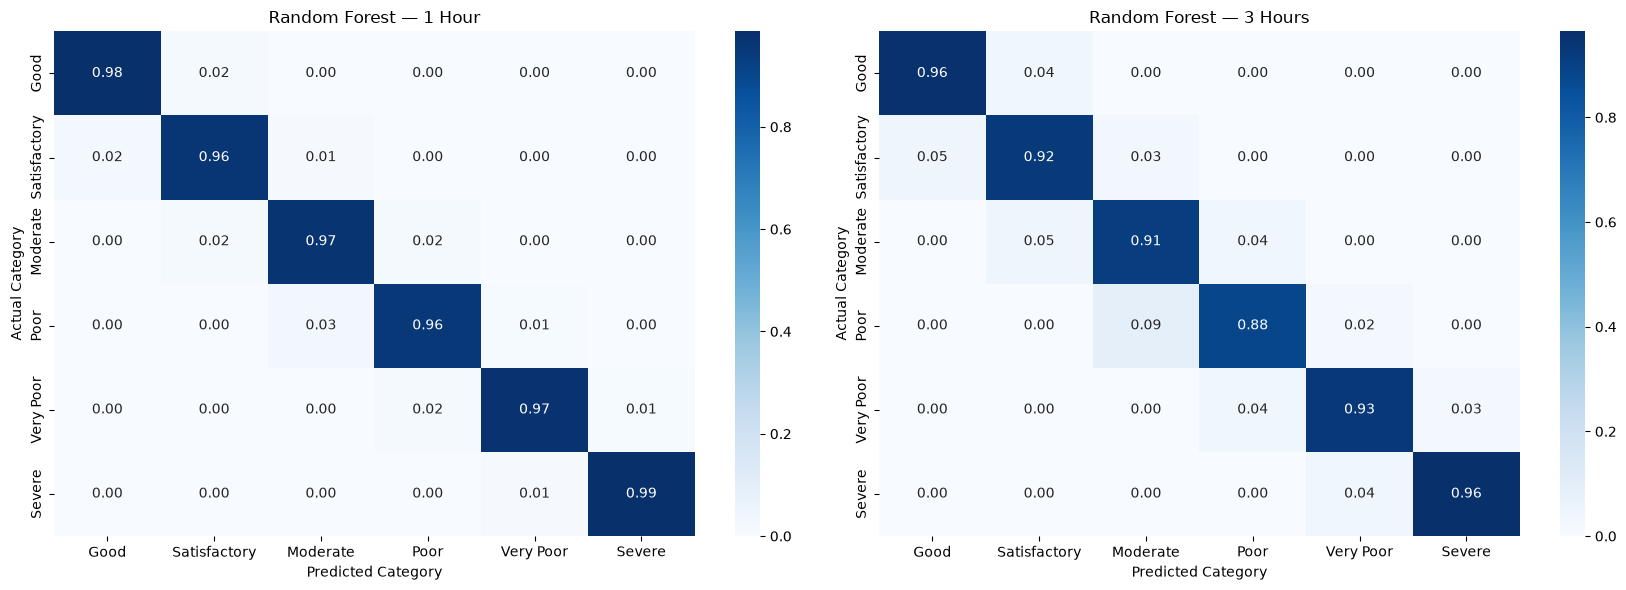

In [19]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

class_order = [
    "Good", "Satisfactory", "Moderate",
    "Poor", "Very Poor", "Severe"
]

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

for ax, y_true, y_pred, title in [
    (axes[0], y_test_1h, pred_1h, "Random Forest — 1 Hour"),
    (axes[1], y_test_3h, pred_3h, "Random Forest — 3 Hours")
]:
    cm = confusion_matrix(
        y_true, y_pred, labels=class_order,
        normalize="true"
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        xticklabels=class_order,
        yticklabels=class_order,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted Category")
    ax.set_ylabel("Actual Category")

plt.tight_layout()
plt.show()


In [20]:

import numpy as np
import pandas as pd

categories = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

# Category distance-based cost matrix.
# Underestimating pollution is penalized more heavily.
cost_matrix = np.array([
    [0, 1, 3, 6, 10, 15],
    [2, 0, 1, 4, 8, 13],
    [4, 2, 0, 1, 5, 10],
    [7, 5, 2, 0, 1, 6],
    [11, 9, 6, 2, 0, 1],
    [16, 14, 11, 7, 2, 0]
])

def calculate_cost(y_true, y_pred):
    true_idx = pd.Categorical(
        y_true, categories=categories
    ).codes

    pred_idx = pd.Categorical(
        y_pred, categories=categories
    ).codes

    costs = cost_matrix[true_idx, pred_idx]

    return costs.mean()

print("Random Forest — 1 hour cost:",
      round(calculate_cost(y_test_1h, pred_1h), 4))

print("Random Forest — 3 hours cost:",
      round(calculate_cost(y_test_3h, pred_3h), 4))


Random Forest — 1 hour cost: 0.0448
Random Forest — 3 hours cost: 0.1058


In [21]:
# Persistence predictions
baseline_pred_1h = (
    test_df.dropna(subset=["pm25_aqi_category", "target_1h"])
    ["pm25_aqi_category"]
)
baseline_true_1h = (
    test_df.dropna(subset=["pm25_aqi_category", "target_1h"])
    ["target_1h"]
)

baseline_pred_3h = (
    test_df.dropna(subset=["pm25_aqi_category", "target_3h"])
    ["pm25_aqi_category"]
)
baseline_true_3h = (
    test_df.dropna(subset=["pm25_aqi_category", "target_3h"])
    ["target_3h"]
)

print("Persistence 1-hour cost:",
      round(calculate_cost(baseline_true_1h, baseline_pred_1h), 4))

print("Persistence 3-hour cost:",
      round(calculate_cost(baseline_true_3h, baseline_pred_3h), 4))

Persistence 1-hour cost: 0.0477
Persistence 3-hour cost: 0.1263


In [22]:

# Check for future-information columns in model inputs

forbidden_columns = [
    "PM25_next_1h",
    "PM25_next_3h",
    "target_1h",
    "target_3h"
]

print("Forbidden columns included in features:")
print(set(feature_columns).intersection(forbidden_columns))

# Check chronological separation
print("\nTraining maximum timestamp:")
print(train_df["observed_at_ist"].max())

print("\nTesting minimum timestamp:")
print(test_df["observed_at_ist"].min())

# Check that the final training labels do not cross
# into the test period
print("\nTraining boundary:")
print("Split timestamp:", split_time)
print(
    "Last training timestamp:",
    train_df["observed_at_ist"].max()
)

# Check feature availability
print("\nRolling feature columns:")
print([
    c for c in feature_columns
    if "rolling" in c or "lag" in c
])

print("\nCurrent and future PM2.5 columns:")
print([
    c for c in model_df.columns
    if "PM25_next" in c or c.startswith("target_")
])


Forbidden columns included in features:
set()

Training maximum timestamp:
2026-07-10 20:00:00+05:30

Testing minimum timestamp:
2026-07-11 00:00:00+05:30

Training boundary:
Split timestamp: 2026-07-11 00:00:00+05:30
Last training timestamp: 2026-07-10 20:00:00+05:30

Rolling feature columns:
['pm25_lag_1', 'pm25_lag_3', 'pm25_lag_6', 'pm25_lag_12', 'pm25_lag_24', 'pm25_rolling_mean_6h', 'pm25_rolling_mean_12h', 'pm25_rolling_mean_24h', 'pm25_rolling_std_24h']

Current and future PM2.5 columns:
['PM25_next_1h', 'PM25_next_3h', 'target_1h', 'target_3h']


In [23]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split

In [24]:

# KNN: stratified sample for manageable computation
X_knn_1h, _, y_knn_1h, _ = train_test_split(
    X_train_1h,
    y_train_1h,
    train_size=0.30,
    stratify=y_train_1h,
    random_state=42
)

X_knn_3h, _, y_knn_3h, _ = train_test_split(
    X_train_3h,
    y_train_3h,
    train_size=0.30,
    stratify=y_train_3h,
    random_state=42
)

knn_model_1h = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", KNeighborsClassifier(
        n_neighbors=7,
        weights="distance",
        n_jobs=-1
    ))
])

knn_model_3h = clone(knn_model_1h)

print("Training KNN models...")

knn_model_1h.fit(X_knn_1h, y_knn_1h)
knn_model_3h.fit(X_knn_3h, y_knn_3h)

print("KNN models trained!")


# Gradient Boosting: full training data
gb_model_1h = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gb_model_3h = clone(gb_model_1h)

print("Training Gradient Boosting models...")

gb_model_1h.fit(X_train_1h, y_train_1h)
gb_model_3h.fit(X_train_3h, y_train_3h)

print("Gradient Boosting models trained!")


Training KNN models...
KNN models trained!
Training Gradient Boosting models...
Gradient Boosting models trained!


In [25]:
import joblib

# Collect the four trained models
additional_models = {
    "knn_1h": knn_model_1h,
    "knn_3h": knn_model_3h,
    "gradient_boosting_1h": gb_model_1h,
    "gradient_boosting_3h": gb_model_3h
}

# Save each model individually
for name, model in additional_models.items():
    file_path = MODEL_DIR / f"{name}.joblib"
    joblib.dump(model, file_path)
    print(f"Saved: {file_path.name}")

# Save these four together as a bundle
joblib.dump(
    additional_models,
    MODEL_DIR / "knn_gradient_boosting_bundle.joblib"
)

print("\nAll four additional models saved successfully!")

Saved: knn_1h.joblib
Saved: knn_3h.joblib
Saved: gradient_boosting_1h.joblib
Saved: gradient_boosting_3h.joblib

All four additional models saved successfully!


In [26]:
for name in additional_models:
    path = MODEL_DIR / f"{name}.joblib"
    loaded_model = joblib.load(path)
    print(name, "→ Verified successfully")

knn_1h → Verified successfully
knn_3h → Verified successfully
gradient_boosting_1h → Verified successfully
gradient_boosting_3h → Verified successfully


In [27]:
from sklearn.utils.validation import check_is_fitted

for horizon, model_dict in [
    ("1-hour", regularized_models_1h),
    ("3-hour", regularized_models_3h)
]:
    for penalty in ["l1", "l2"]:
        model = model_dict[penalty]
        classifier = model.named_steps["classifier"]

        try:
            check_is_fitted(classifier)
            print(
                f"{penalty.upper()} {horizon}: FITTED | "
                f"Iterations: {classifier.n_iter_}"
            )
        except Exception:
            print(f"{penalty.upper()} {horizon}: NOT FITTED")

NameError: name 'regularized_models_1h' is not defined

In [29]:
# Regularization experiments: L1 vs L2

regularized_models_1h = {}
regularized_models_3h = {}

for penalty in ["l1", "l2"]:

    l1_ratio = 1.0 if penalty == "l1" else 0.0

    model_1h = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(
            C=1.0,
            l1_ratio=l1_ratio,
            solver="saga",
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    model_3h = clone(model_1h)

    regularized_models_1h[penalty] = model_1h
    regularized_models_3h[penalty] = model_3h

print("L1 and L2 regularization pipelines prepared!")

L1 and L2 regularization pipelines prepared!


In [30]:
print("Training L1 — 1 hour...")

regularized_models_1h["l1"].fit(
    X_train_1h, y_train_1h
)

joblib.dump(
    regularized_models_1h["l1"],
    MODEL_DIR / "regularized_l1_1h.joblib"
)

print("L1 1-hour trained and saved!")

Training L1 — 1 hour...
L1 1-hour trained and saved!


C:\Users\anshu\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


## don't run 


In [24]:
# Train L1 and L2 models for both forecasting horizons

for penalty in ["l1", "l2"]:

    print(f"\nTraining {penalty.upper()} models...")

    regularized_models_1h[penalty].fit(
        X_train_1h, y_train_1h
    )

    print(f"{penalty.upper()} 1-hour model trained!")

    regularized_models_3h[penalty].fit(
        X_train_3h, y_train_3h
    )

    print(f"{penalty.upper()} 3-hour model trained!")

print("\nAll regularization models trained!")


Training L1 models...
L1 3-hour model trained!

Training L2 models...
L2 1-hour model trained!
L2 3-hour model trained!

All regularization models trained!


In [1]:
from sklearn.utils.validation import check_is_fitted

model_groups = {
    "Baseline 1-hour": models_1h,
    "Baseline 3-hour": models_3h,
    "L1 1-hour": {"L1": regularized_models_1h["l1"]},
    "L1 3-hour": {"L1": regularized_models_3h["l1"]},
    "L2 1-hour": {"L2": regularized_models_1h["l2"]},
    "L2 3-hour": {"L2": regularized_models_3h["l2"]},
    "KNN": {"KNN": knn_model_1h, "KNN 3h": knn_model_3h},
    "Gradient Boosting": {"GB": gb_model_1h, "GB 3h": gb_model_3h}
}

for group, models in model_groups.items():
    for name, model in models.items():
        try:
            check_is_fitted(model.named_steps["classifier"])
            print(f"{group} - {name}: FITTED")
        except Exception:
            print(f"{group} - {name}: NOT FITTED")

NameError: name 'models_1h' is not defined

In [4]:
for name, obj in globals().items():
    if not name.startswith("_"):
        if isinstance(obj, dict):
            if any("model" in str(k).lower() for k in obj.keys()):
                print(f"\n{name}:")
                print("Keys:", list(obj.keys()))

        elif hasattr(obj, "named_steps"):
            print(f"{name}: Pipeline")

RuntimeError: dictionary changed size during iteration

In [5]:
from pathlib import Path

models_folder = Path("../models")

print("Models folder exists:", models_folder.exists())

if models_folder.exists():
    files = list(models_folder.rglob("*"))

    if not files:
        print("Models folder is empty.")

    for file in files:
        if file.is_file():
            size_mb = file.stat().st_size / (1024 * 1024)
            print(f"{file.name}  |  {size_mb:.2f} MB")

Models folder exists: True
Models folder is empty.


In [7]:
from pathlib import Path

project_path = Path.cwd().parent

for file in project_path.rglob("*"):
    if file.is_file() and file.suffix.lower() in [".pkl", ".joblib", ".sav"]:
        print(file)

In [9]:
from pathlib import Path

old_models_folder = Path(r"C:\Users\anshu\Desktop\ML project\aqi-intelligence\aqi-intelligence\datanew\models")

model_files = list(old_models_folder.glob("*.joblib"))

print("Total saved models:", len(model_files))

for file in model_files:
    print(file.name)

Total saved models: 30
Alipur,_Delhi_-_DPCC_1h.joblib
Alipur,_Delhi_-_DPCC_3h.joblib
Anand_Vihar,_New_Delhi_-_DPCC_1h.joblib
Anand_Vihar,_New_Delhi_-_DPCC_3h.joblib
Aya_Nagar,_New_Delhi_-_IMD_1h.joblib
Aya_Nagar,_New_Delhi_-_IMD_3h.joblib
Bawana,_Delhi_-_DPCC_1h.joblib
Bawana,_Delhi_-_DPCC_3h.joblib
Dwarka-Sector_8,_Delhi_-_DPCC_1h.joblib
Dwarka-Sector_8,_Delhi_-_DPCC_3h.joblib
ITO,_New_Delhi_-_CPCB_1h.joblib
ITO,_New_Delhi_-_CPCB_3h.joblib
Lodhi_Road,_New_Delhi_-_IMD_1h.joblib
Lodhi_Road,_New_Delhi_-_IMD_3h.joblib
Mandir_Marg,_New_Delhi_-_DPCC_1h.joblib
Mandir_Marg,_New_Delhi_-_DPCC_3h.joblib
Mundka,_Delhi_-_DPCC_1h.joblib
Mundka,_Delhi_-_DPCC_3h.joblib
Patparganj,_Delhi_-_DPCC_1h.joblib
Patparganj,_Delhi_-_DPCC_3h.joblib
Punjabi_Bagh,_Delhi_-_DPCC_1h.joblib
Punjabi_Bagh,_Delhi_-_DPCC_3h.joblib
Pusa,_Delhi_-_DPCC_1h.joblib
Pusa,_Delhi_-_DPCC_3h.joblib
Rohini,_Delhi_-_DPCC_1h.joblib
Rohini,_Delhi_-_DPCC_3h.joblib
R_K_Puram,_Delhi_-_DPCC_1h.joblib
R_K_Puram,_Delhi_-_DPCC_3h.joblib
Vivek

In [11]:
import joblib

sample_model_path = old_models_folder / "Anand_Vihar,_New_Delhi_-_DPCC_1h.joblib"

sample_model = joblib.load(sample_model_path)

print("Model type:", type(sample_model))
print("\nModel details:")
print(sample_model)

Model type: <class 'sklearn.pipeline.Pipeline'>

Model details:
Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['co_ppm', 'no_ppb',
                                                   'no2_ppb', 'nox_ppb',
                                                   'o3_ppb', 'pm10_ug_m3',
                                                   'pm25_ug_m3', 'rh_percent',
                                                   'so2_ppb', 'temp_celsius',
                                                   'wind_dir_deg',
                                                   'wind_spe

In [12]:
if hasattr(sample_model, "feature_names_in_"):
    print("Expected features:")
    print(sample_model.feature_names_in_)

elif hasattr(sample_model, "named_steps"):
    print("Pipeline steps:", sample_model.named_steps.keys())

    for name, step in sample_model.named_steps.items():
        if hasattr(step, "feature_names_in_"):
            print(name, step.feature_names_in_)

else:
    print("No direct feature_names_in_ attribute.")

Expected features:
['co_ppm' 'no_ppb' 'no2_ppb' 'nox_ppb' 'o3_ppb' 'pm10_ug_m3' 'pm25_ug_m3'
 'rh_percent' 'so2_ppb' 'temp_celsius' 'wind_dir_deg' 'wind_speed_m_s'
 'co_ppm_lag_1h' 'no_ppb_lag_1h' 'no2_ppb_lag_1h' 'nox_ppb_lag_1h'
 'o3_ppb_lag_1h' 'pm10_ug_m3_lag_1h' 'pm25_ug_m3_lag_1h'
 'rh_percent_lag_1h' 'so2_ppb_lag_1h' 'temp_celsius_lag_1h'
 'wind_dir_deg_lag_1h' 'wind_speed_m_s_lag_1h' 'co_ppm_lag_3h'
 'no_ppb_lag_3h' 'no2_ppb_lag_3h' 'nox_ppb_lag_3h' 'o3_ppb_lag_3h'
 'pm10_ug_m3_lag_3h' 'pm25_ug_m3_lag_3h' 'rh_percent_lag_3h'
 'so2_ppb_lag_3h' 'temp_celsius_lag_3h' 'wind_dir_deg_lag_3h'
 'wind_speed_m_s_lag_3h' 'co_ppm_lag_6h' 'no_ppb_lag_6h' 'no2_ppb_lag_6h'
 'nox_ppb_lag_6h' 'o3_ppb_lag_6h' 'pm10_ug_m3_lag_6h' 'pm25_ug_m3_lag_6h'
 'rh_percent_lag_6h' 'so2_ppb_lag_6h' 'temp_celsius_lag_6h'
 'wind_dir_deg_lag_6h' 'wind_speed_m_s_lag_6h' 'co_ppm_lag_12h'
 'no_ppb_lag_12h' 'no2_ppb_lag_12h' 'nox_ppb_lag_12h' 'o3_ppb_lag_12h'
 'pm10_ug_m3_lag_12h' 'pm25_ug_m3_lag_12h' 'rh_percent_l

In [13]:
print("Model classes:")
print(sample_model.named_steps["clf"].classes_)

print("\nPipeline steps:")
print(sample_model.named_steps.keys())

print("\nExpected feature count:")
print(len(sample_model.feature_names_in_))

Model classes:
['Good' 'Moderate' 'Poor' 'Satisfactory' 'Severe' 'Very Poor']

Pipeline steps:
dict_keys(['preprocess', 'clf'])

Expected feature count:
132


In [15]:
model_3h = joblib.load(
    old_models_folder / "Anand_Vihar,_New_Delhi_-_DPCC_3h.joblib"
)

print("1-hour classes:", sample_model.named_steps["clf"].classes_)
print("3-hour classes:", model_3h.named_steps["clf"].classes_)

1-hour classes: ['Good' 'Moderate' 'Poor' 'Satisfactory' 'Severe' 'Very Poor']
3-hour classes: ['Good' 'Moderate' 'Poor' 'Satisfactory' 'Severe' 'Very Poor']


In [16]:
print("Model expects these features:")
print(sample_model.feature_names_in_[:15])

print("\nNumber of features:", len(sample_model.feature_names_in_))

print("\nModel prediction test:")
print("Classifier:", type(sample_model.named_steps["clf"]).__name__)

Model expects these features:
['co_ppm' 'no_ppb' 'no2_ppb' 'nox_ppb' 'o3_ppb' 'pm10_ug_m3' 'pm25_ug_m3'
 'rh_percent' 'so2_ppb' 'temp_celsius' 'wind_dir_deg' 'wind_speed_m_s'
 'co_ppm_lag_1h' 'no_ppb_lag_1h' 'no2_ppb_lag_1h']

Number of features: 132

Model prediction test:
Classifier: HistGradientBoostingClassifier


In [17]:
from pathlib import Path

for folder in [Path("../data"), old_models_folder.parent]:
    print("\nFolder:", folder.resolve())

    if folder.exists():
        for file in folder.iterdir():
            if file.is_file():
                print(file.name)


Folder: C:\Users\anshu\Desktop\ML project\aqi-intelligence\aqi-intelligence\datanew\aqi_rebuild\data
feature_engineered_dataset.csv
pm25_forecasting_dataset.csv
reconstructed_hourly_data.csv

Folder: C:\Users\anshu\Desktop\ML project\aqi-intelligence\aqi-intelligence\datanew
active_sensors_by_station.json
append_latest_reading.py
check_coverage.py
check_repeats.py
cleaned_hourly_air_quality.csv
cleaned_hourly_air_quality_test.csv
copy_assets.py
coverage_mismatch_report.csv
data_quality_report.json
data_quality_report.py
delhi_matched_locations.json
eda.py
features_hourly_air_quality.csv
feature_engineering.py
fetch_live_openaq.py
forecast_latest.py
forecast_real.py
generate_yearly_calendar_data.py
hourly_air_quality_raw.csv
model_selection_report.csv
preprocess_hourly.py
README.md
reduced_stations_15.json
run_latest_pipeline.bat
save_best_models.py
split_dataset.py
stations_forecast.csv
stations_sensor_catalog.json
stations_summary.csv
target_creation.py
target_hourly_air_quality.csv


## continue 

In [31]:
import joblib
from pathlib import Path

# Folder containing saved models
MODEL_DIR = Path("../models")

# Load all saved models
model_files = {
    "Logistic Regression": (
        "logistic_regression_1h.joblib",
        "logistic_regression_3h.joblib"
    ),
    "Decision Tree": (
        "decision_tree_1h.joblib",
        "decision_tree_3h.joblib"
    ),
    "Random Forest": (
        "random_forest_1h.joblib",
        "random_forest_3h.joblib"
    ),
    "Extra Trees": (
        "extra_trees_1h.joblib",
        "extra_trees_3h.joblib"
    ),
    "KNN": (
        "knn_1h.joblib",
        "knn_3h.joblib"
    ),
    "Gradient Boosting": (
        "gradient_boosting_1h.joblib",
        "gradient_boosting_3h.joblib"
    )
}

models_1h = {}
models_3h = {}

for name, (file_1h, file_3h) in model_files.items():

    models_1h[name] = joblib.load(MODEL_DIR / file_1h)
    models_3h[name] = joblib.load(MODEL_DIR / file_3h)

    print(f"{name}: Both horizons loaded successfully!")

print("\nAll 12 saved models loaded!")

Logistic Regression: Both horizons loaded successfully!
Decision Tree: Both horizons loaded successfully!
Random Forest: Both horizons loaded successfully!
Extra Trees: Both horizons loaded successfully!
KNN: Both horizons loaded successfully!
Gradient Boosting: Both horizons loaded successfully!

All 12 saved models loaded!


In [32]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []
predictions_1h = {}
predictions_3h = {}

# Evaluate 1-hour and 3-hour models
for name in models_1h:

    print(f"\nEvaluating {name}...")

    # 1-hour prediction
    pred_1h = models_1h[name].predict(X_test_1h)
    predictions_1h[name] = pred_1h

    results.append({
        "Model": name,
        "Horizon": "1-hour",
        "Accuracy": accuracy_score(y_test_1h, pred_1h),
        "Precision": precision_score(
            y_test_1h, pred_1h, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test_1h, pred_1h, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test_1h, pred_1h, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test_1h, pred_1h, average="weighted", zero_division=0
        )
    })

    print(f"{name} — 1-hour complete")

    # 3-hour prediction
    pred_3h = models_3h[name].predict(X_test_3h)
    predictions_3h[name] = pred_3h

    results.append({
        "Model": name,
        "Horizon": "3-hour",
        "Accuracy": accuracy_score(y_test_3h, pred_3h),
        "Precision": precision_score(
            y_test_3h, pred_3h, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test_3h, pred_3h, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test_3h, pred_3h, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test_3h, pred_3h, average="weighted", zero_division=0
        )
    })

    print(f"{name} — 3-hour complete")

results_df = pd.DataFrame(results)

print("\nALL MODEL EVALUATIONS COMPLETED!")



Evaluating Logistic Regression...
Logistic Regression — 1-hour complete
Logistic Regression — 3-hour complete

Evaluating Decision Tree...
Decision Tree — 1-hour complete
Decision Tree — 3-hour complete

Evaluating Random Forest...
Random Forest — 1-hour complete
Random Forest — 3-hour complete

Evaluating Extra Trees...
Extra Trees — 1-hour complete
Extra Trees — 3-hour complete

Evaluating KNN...
KNN — 1-hour complete
KNN — 3-hour complete

Evaluating Gradient Boosting...
Gradient Boosting — 1-hour complete
Gradient Boosting — 3-hour complete

ALL MODEL EVALUATIONS COMPLETED!


In [33]:

comparison_df = results_df.copy()

metric_columns = [
    "Accuracy", "Precision", "Recall", "Macro F1", "Weighted F1"
]

comparison_df[metric_columns] = (
    comparison_df[metric_columns] * 100
).round(2)

comparison_df = comparison_df.sort_values(
    ["Horizon", "Macro F1"],
    ascending=[True, False]
)

display(comparison_df)


,Model,Horizon,Accuracy,Precision,Recall,Macro F1,Weighted F1
10,Gradient Boosting,1-hour,97.74,97.61,97.55,97.58,97.74
4,Random Forest,1-hour,97.11,96.61,97.16,96.88,97.11
2,Decision Tree,1-hour,96.81,96.61,96.54,96.57,96.81
0,Logistic Regression,1-hour,94.79,93.83,95.58,94.60,94.81
6,Extra Trees,1-hour,94.21,94.34,92.84,93.54,94.18
8,KNN,1-hour,60.20,64.95,57.11,58.95,58.16
11,Gradient Boosting,3-hour,93.90,93.58,93.16,93.37,93.89
5,Random Forest,3-hour,93.18,92.12,92.95,92.51,93.19
1,Logistic Regression,3-hour,90.65,89.18,91.42,90.13,90.67
7,Extra Trees,3-hour,90.62,90.32,88.49,89.34,90.56



Gradient Boosting — 1h CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Good       0.98      0.98      0.98      8582
    Moderate       0.97      0.97      0.97      5566
        Poor       0.95      0.95      0.95      1902
Satisfactory       0.98      0.98      0.98     13026
      Severe       0.99      0.99      0.99      1656
   Very Poor       0.99      0.98      0.99      3351

    accuracy                           0.98     34083
   macro avg       0.98      0.98      0.98     34083
weighted avg       0.98      0.98      0.98     34083



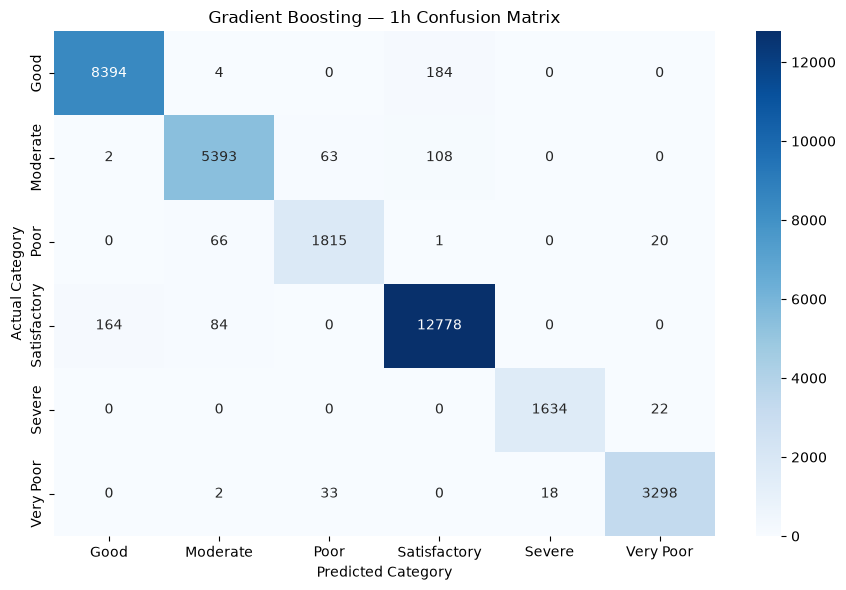


Random Forest — 1h CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Good       0.97      0.98      0.97      8582
    Moderate       0.96      0.97      0.96      5566
        Poor       0.93      0.96      0.94      1902
Satisfactory       0.98      0.96      0.97     13026
      Severe       0.98      0.99      0.98      1656
   Very Poor       0.99      0.97      0.98      3351

    accuracy                           0.97     34083
   macro avg       0.97      0.97      0.97     34083
weighted avg       0.97      0.97      0.97     34083



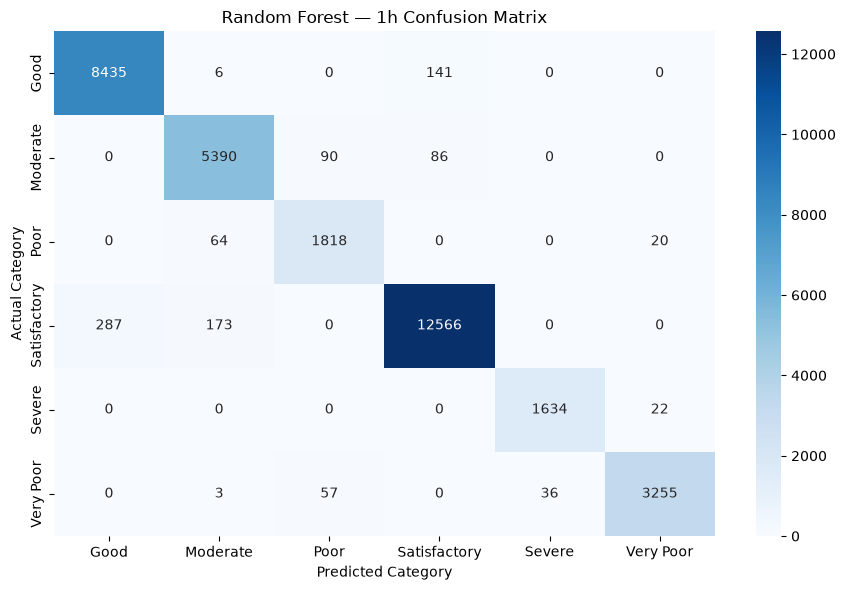


Gradient Boosting — 3h CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Good       0.95      0.95      0.95      8560
    Moderate       0.92      0.91      0.91      5566
        Poor       0.87      0.86      0.87      1902
Satisfactory       0.94      0.95      0.94     13022
      Severe       0.97      0.96      0.97      1656
   Very Poor       0.96      0.96      0.96      3351

    accuracy                           0.94     34057
   macro avg       0.94      0.93      0.93     34057
weighted avg       0.94      0.94      0.94     34057



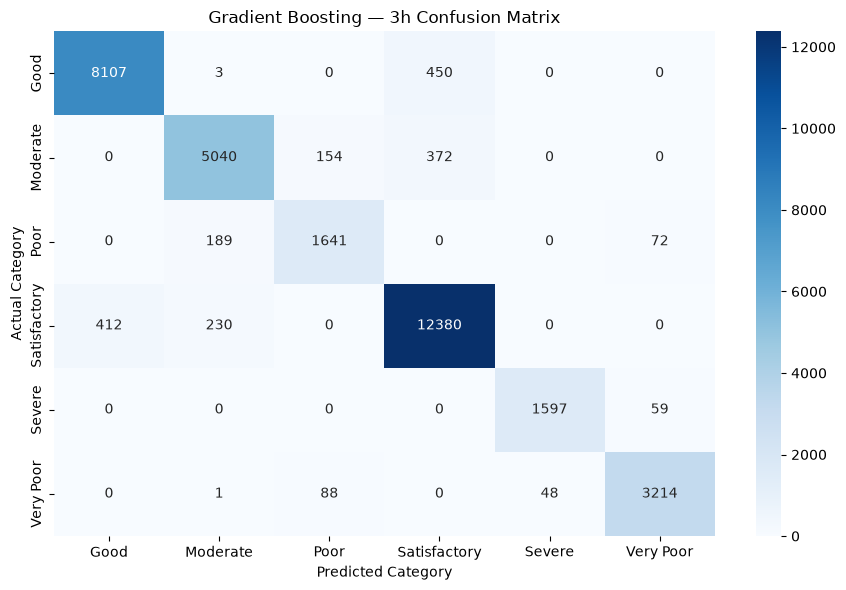


Random Forest — 3h CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Good       0.93      0.96      0.95      8560
    Moderate       0.90      0.91      0.91      5566
        Poor       0.83      0.88      0.86      1902
Satisfactory       0.95      0.92      0.94     13022
      Severe       0.95      0.96      0.96      1656
   Very Poor       0.97      0.93      0.95      3351

    accuracy                           0.93     34057
   macro avg       0.92      0.93      0.93     34057
weighted avg       0.93      0.93      0.93     34057



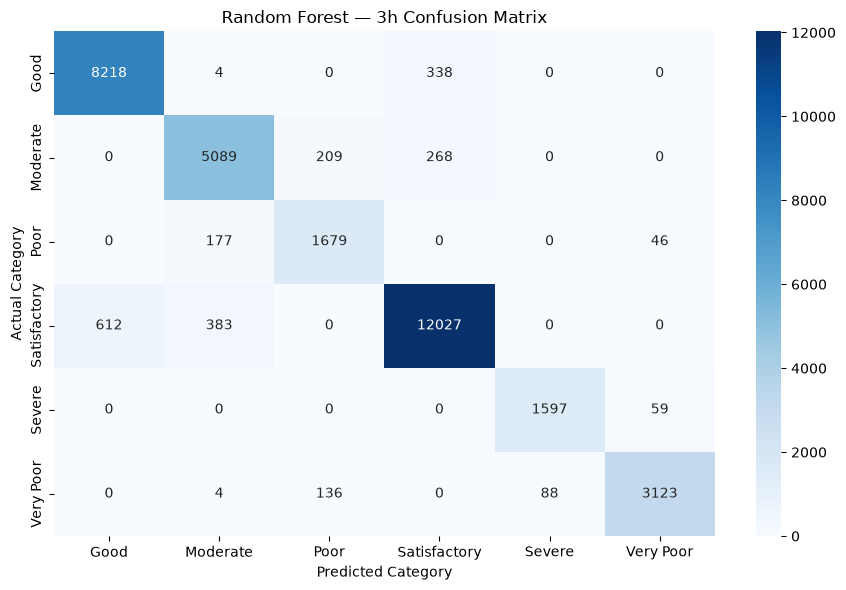


Comparison table and confusion matrices saved!


In [34]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from pathlib import Path

RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save the complete comparison table
results_df.to_csv(
    RESULTS_DIR / "six_model_comparison.csv",
    index=False
)

# Inspect our two leading models
models_to_inspect = ["Gradient Boosting", "Random Forest"]

for horizon, y_true, predictions in [
    ("1h", y_test_1h, predictions_1h),
    ("3h", y_test_3h, predictions_3h)
]:

    for model_name in models_to_inspect:

        y_pred = predictions[model_name]

        print("\n" + "=" * 65)
        print(f"{model_name} — {horizon} CLASSIFICATION REPORT")
        print("=" * 65)

        print(classification_report(
            y_true,
            y_pred,
            zero_division=0
        ))

        labels = models_1h[model_name].named_steps[
            "classifier"
        ].classes_

        cm = confusion_matrix(
            y_true,
            y_pred,
            labels=labels
        )

        plt.figure(figsize=(9, 6))

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=labels,
            yticklabels=labels
        )

        plt.title(f"{model_name} — {horizon} Confusion Matrix")
        plt.xlabel("Predicted Category")
        plt.ylabel("Actual Category")
        plt.tight_layout()

        filename = (
            f"{model_name.lower().replace(' ', '_')}_{horizon}_confusion.png"
        )

        plt.savefig(
            RESULTS_DIR / filename,
            dpi=200,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

print("\nComparison table and confusion matrices saved!")


In [35]:

# Cost-sensitive evaluation for all six models

cost_results = []

for name in models_1h:

    cost_1h = calculate_cost(
        y_test_1h,
        predictions_1h[name]
    )

    cost_3h = calculate_cost(
        y_test_3h,
        predictions_3h[name]
    )

    cost_results.append({
        "Model": name,
        "1-hour Average Cost": cost_1h,
        "3-hour Average Cost": cost_3h
    })

cost_df = pd.DataFrame(cost_results)

cost_df = cost_df.sort_values("1-hour Average Cost")

display(cost_df.round(4))

# Save results
cost_df.to_csv(
    RESULTS_DIR / "cost_sensitive_comparison.csv",
    index=False
)


,Model,1-hour Average Cost,3-hour Average Cost
5,Gradient Boosting,0.0350,0.0942
2,Random Forest,0.0448,0.1058
1,Decision Tree,0.0490,0.1470
0,Logistic Regression,0.0880,0.1486
3,Extra Trees,0.0928,0.1491
4,KNN,0.6986,0.6822


In [36]:

# Save final evaluation artifacts

results_df.to_csv(
    RESULTS_DIR / "final_model_metrics.csv",
    index=False
)

cost_df.to_csv(
    RESULTS_DIR / "final_cost_comparison.csv",
    index=False
)

# Save selected models separately for easy dashboard integration
import joblib

joblib.dump(
    models_1h["Gradient Boosting"],
    MODEL_DIR / "best_model_1h.joblib"
)

joblib.dump(
    models_3h["Gradient Boosting"],
    MODEL_DIR / "best_model_3h.joblib"
)

print("Final evaluation results saved!")
print("Best 1-hour and 3-hour models saved!")


Final evaluation results saved!
Best 1-hour and 3-hour models saved!


In [37]:

# Inspect the current best models before tuning

for horizon, model in [
    ("1-hour", models_1h["Gradient Boosting"]),
    ("3-hour", models_3h["Gradient Boosting"])
]:
    print(f"\n{horizon} Gradient Boosting")
    print(model.named_steps["classifier"].get_params())



1-hour Gradient Boosting
{'ccp_alpha': 0.0, 'criterion': 'deprecated', 'init': None, 'learning_rate': 0.1, 'loss': 'log_loss', 'max_depth': 3, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'n_estimators': 100, 'n_iter_no_change': None, 'random_state': 42, 'subsample': 1.0, 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}

3-hour Gradient Boosting
{'ccp_alpha': 0.0, 'criterion': 'deprecated', 'init': None, 'learning_rate': 0.1, 'loss': 'log_loss', 'max_depth': 3, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'n_estimators': 100, 'n_iter_no_change': None, 'random_state': 42, 'subsample': 1.0, 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}


In [38]:

# Prepare chronological validation data for tuning
# Original test data remains untouched.

import numpy as np
import pandas as pd

# Sort unique timestamps from the training data
unique_train_times = np.array(
    sorted(train_df["observed_at_ist"].unique())
)

# Use the first 80% for tuning training
# and the last 20% for validation.
validation_cutoff_index = int(len(unique_train_times) * 0.80)

validation_split_time = pd.Timestamp(
    unique_train_times[validation_cutoff_index]
)

# Purge the final 3 hours from tuning training
tuning_train_df = train_df[
    train_df["observed_at_ist"] <
    (validation_split_time - pd.Timedelta(hours=3))
].copy()

tuning_val_df = train_df[
    train_df["observed_at_ist"] >= validation_split_time
].copy()

print("TUNING DATA PREPARATION")
print("=" * 45)

print("Tuning training rows:", len(tuning_train_df))
print("Validation rows:", len(tuning_val_df))

print("\nTuning training ends:")
print(tuning_train_df["observed_at_ist"].max())

print("\nValidation begins:")
print(tuning_val_df["observed_at_ist"].min())

print("\nOriginal final test begins:")
print(test_df["observed_at_ist"].min())


TUNING DATA PREPARATION
Tuning training rows: 126462
Validation rows: 31629

Tuning training ends:
2026-03-31 08:00:00+05:30

Validation begins:
2026-03-31 12:00:00+05:30

Original final test begins:
2026-07-11 00:00:00+05:30


In [39]:

# Prepare tuning datasets for both horizons

def prepare_tuning_data(target):

    train_valid = tuning_train_df.dropna(
        subset=[target]
    ).copy()

    val_valid = tuning_val_df.dropna(
        subset=[target]
    ).copy()

    X_train = train_valid[feature_columns]
    y_train = train_valid[target]

    X_val = val_valid[feature_columns]
    y_val = val_valid[target]

    return X_train, X_val, y_train, y_val


# 1-hour
X_tune_train_1h, X_val_1h, y_tune_train_1h, y_val_1h = (
    prepare_tuning_data("target_1h")
)

# 3-hour
X_tune_train_3h, X_val_3h, y_tune_train_3h, y_val_3h = (
    prepare_tuning_data("target_3h")
)

print("1-HOUR TUNING DATA")
print("Training:", X_tune_train_1h.shape)
print("Validation:", X_val_1h.shape)

print("\n3-HOUR TUNING DATA")
print("Training:", X_tune_train_3h.shape)
print("Validation:", X_val_3h.shape)


1-HOUR TUNING DATA
Training: (113827, 45)
Validation: (29032, 45)

3-HOUR TUNING DATA
Training: (113851, 45)
Validation: (29034, 45)


In [40]:

import time
import joblib
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, accuracy_score

# Four configurations, including our original settings
gb_configs = {
    "Original": {
        "n_estimators": 100,
        "learning_rate": 0.10,
        "max_depth": 3,
        "min_samples_leaf": 1
    },
    "Config_A": {
        "n_estimators": 100,
        "learning_rate": 0.05,
        "max_depth": 3,
        "min_samples_leaf": 2
    },
    "Config_B": {
        "n_estimators": 150,
        "learning_rate": 0.10,
        "max_depth": 2,
        "min_samples_leaf": 2
    },
    "Config_C": {
        "n_estimators": 150,
        "learning_rate": 0.05,
        "max_depth": 3,
        "min_samples_leaf": 2
    }
}

tuning_results = []
tuned_models_1h = {}
tuned_models_3h = {}

horizon_data = {
    "1-hour": (
        X_tune_train_1h, y_tune_train_1h,
        X_val_1h, y_val_1h
    ),
    "3-hour": (
        X_tune_train_3h, y_tune_train_3h,
        X_val_3h, y_val_3h
    )
}

for horizon, (X_train, y_train, X_val, y_val) in horizon_data.items():

    for config_name, params in gb_configs.items():

        print(f"\nTraining {config_name} — {horizon}...")
        start_time = time.time()

        model = Pipeline(steps=[
            ("preprocessor", clone(preprocessor)),
            ("classifier", GradientBoostingClassifier(
                **params,
                random_state=42
            ))
        ])

        model.fit(X_train, y_train)

        predictions = model.predict(X_val)

        macro_f1 = f1_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        )

        accuracy = accuracy_score(y_val, predictions)

        avg_cost = calculate_cost(y_val, predictions)

        elapsed = (time.time() - start_time) / 60

        tuning_results.append({
            "Horizon": horizon,
            "Configuration": config_name,
            **params,
            "Accuracy": accuracy,
            "Macro F1": macro_f1,
            "Average Cost": avg_cost,
            "Training Minutes": round(elapsed, 2)
        })

        if horizon == "1-hour":
            tuned_models_1h[config_name] = model
        else:
            tuned_models_3h[config_name] = model

        print(
            f"Completed | Macro F1: {macro_f1:.4f} "
            f"| Cost: {avg_cost:.4f} "
            f"| Time: {elapsed:.2f} min"
        )

print("\nALL HYPERPARAMETER EXPERIMENTS COMPLETED!")

tuning_df = pd.DataFrame(tuning_results)

display(
    tuning_df.sort_values(
        ["Horizon", "Macro F1"],
        ascending=[True, False]
    )
)



Training Original — 1-hour...
Completed | Macro F1: 0.9628 | Cost: 0.0428 | Time: 14.60 min

Training Config_A — 1-hour...
Completed | Macro F1: 0.9613 | Cost: 0.0454 | Time: 15.13 min

Training Config_B — 1-hour...
Completed | Macro F1: 0.9633 | Cost: 0.0422 | Time: 16.02 min

Training Config_C — 1-hour...
Completed | Macro F1: 0.9633 | Cost: 0.0424 | Time: 25.51 min

Training Original — 3-hour...
Completed | Macro F1: 0.8941 | Cost: 0.1230 | Time: 16.34 min

Training Config_A — 3-hour...
Completed | Macro F1: 0.8878 | Cost: 0.1307 | Time: 13.04 min

Training Config_B — 3-hour...
Completed | Macro F1: 0.8916 | Cost: 0.1272 | Time: 13.32 min

Training Config_C — 3-hour...
Completed | Macro F1: 0.8924 | Cost: 0.1249 | Time: 19.03 min

ALL HYPERPARAMETER EXPERIMENTS COMPLETED!


,Horizon,Configuration,n_estimators,learning_rate,max_depth,min_samples_leaf,Accuracy,Macro F1,Average Cost,Training Minutes
3,1-hour,Config_C,150,0.05,3,2,0.973133,0.963251,0.042401,25.51
2,1-hour,Config_B,150,0.10,2,2,0.972513,0.963250,0.042160,16.02
0,1-hour,Original,100,0.10,3,1,0.972720,0.962814,0.042815,14.60
1,1-hour,Config_A,100,0.05,3,2,0.971032,0.961274,0.045398,15.13
4,3-hour,Original,100,0.10,3,1,0.920886,0.894095,0.122959,16.34
7,3-hour,Config_C,150,0.05,3,2,0.919474,0.892357,0.124888,19.03
6,3-hour,Config_B,150,0.10,2,2,0.917993,0.891603,0.127161,13.32
5,3-hour,Config_A,100,0.05,3,2,0.916064,0.887775,0.130674,13.04


In [42]:
tuning_df.to_csv(
    "../results/hyperparameter_tuning_results.csv",
    index=False
)

print("Hyperparameter tuning results saved successfully!")

Hyperparameter tuning results saved successfully!


In [43]:
required_vars = [
    "X_train_1h", "y_train_1h",
    "X_train_3h", "y_train_3h",
    "X_test_1h", "y_test_1h",
    "X_test_3h", "y_test_3h",
    "preprocessor"
]

for var in required_vars:
    print(f"{var}: {'Available' if var in globals() else 'MISSING'}")

X_train_1h: Available
y_train_1h: Available
X_train_3h: Available
y_train_3h: Available
X_test_1h: Available
y_test_1h: Available
X_test_3h: Available
y_test_3h: Available
preprocessor: Available


In [44]:
from sklearn.pipeline import Pipeline

In [45]:
import time
import joblib
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier

# Final selected configurations
final_configs = {
    "1h": {
        "n_estimators": 150,
        "learning_rate": 0.05,
        "max_depth": 3,
        "min_samples_leaf": 2,
        "random_state": 42
    },
    "3h": {
        "n_estimators": 100,
        "learning_rate": 0.10,
        "max_depth": 3,
        "min_samples_leaf": 1,
        "random_state": 42
    }
}

final_models = {}

for horizon, config in final_configs.items():

    print(f"\nTraining final {horizon} model...")

    start_time = time.time()

    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", GradientBoostingClassifier(**config))
    ])

    if horizon == "1h":
        model.fit(X_train_1h, y_train_1h)
    else:
        model.fit(X_train_3h, y_train_3h)

    elapsed = (time.time() - start_time) / 60

    final_models[horizon] = model

    print(f"Completed in {elapsed:.2f} minutes")


Training final 1h model...
Completed in 25.41 minutes

Training final 3h model...
Completed in 17.39 minutes


In [46]:
import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    final_models["1h"],
    MODEL_DIR / "gradient_boosting_final_1h.joblib"
)

joblib.dump(
    final_models["3h"],
    MODEL_DIR / "gradient_boosting_final_3h.joblib"
)

print("Both final models saved successfully!")

Both final models saved successfully!


In [48]:
import joblib

model_1h = joblib.load(MODEL_DIR / "gradient_boosting_final_1h.joblib")
model_3h = joblib.load(MODEL_DIR / "gradient_boosting_final_3h.joblib")

print("1-hour model:", type(model_1h).__name__)
print("3-hour model:", type(model_3h).__name__)

print("\n1-hour model classes:", model_1h.classes_)
print("3-hour model classes:", model_3h.classes_)

print("\nBoth models loaded successfully!")

1-hour model: Pipeline
3-hour model: Pipeline

1-hour model classes: ['Good' 'Moderate' 'Poor' 'Satisfactory' 'Severe' 'Very Poor']
3-hour model classes: ['Good' 'Moderate' 'Poor' 'Satisfactory' 'Severe' 'Very Poor']

Both models loaded successfully!


In [49]:
# Generate predictions using the final saved models

y_pred_1h = model_1h.predict(X_test_1h)
y_pred_3h = model_3h.predict(X_test_3h)

print("1-hour predictions generated:", len(y_pred_1h))
print("3-hour predictions generated:", len(y_pred_3h))

print("\nTest samples:")
print("1-hour:", len(y_test_1h))
print("3-hour:", len(y_test_3h))

1-hour predictions generated: 34083
3-hour predictions generated: 34057

Test samples:
1-hour: 34083
3-hour: 34057


In [50]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Calculate metrics
evaluation_results = []

for horizon, y_true, y_pred in [
    ("1-hour", y_test_1h, y_pred_1h),
    ("3-hour", y_test_3h, y_pred_3h)
]:
    evaluation_results.append({
        "Horizon": horizon,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro"),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted")
    })

evaluation_df = pd.DataFrame(evaluation_results)

print("FINAL MODEL TEST RESULTS")
display(evaluation_df.round(4))

print("\n1-HOUR CLASSIFICATION REPORT")
print(classification_report(y_test_1h, y_pred_1h, digits=4))

print("\n3-HOUR CLASSIFICATION REPORT")
print(classification_report(y_test_3h, y_pred_3h, digits=4))

FINAL MODEL TEST RESULTS


,Horizon,Accuracy,Macro F1,Weighted F1
0,1-hour,0.9772,0.9756,0.9772
1,3-hour,0.9390,0.9337,0.9389



1-HOUR CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Good     0.9805    0.9787    0.9796      8582
    Moderate     0.9711    0.9675    0.9693      5566
        Poor     0.9479    0.9564    0.9521      1902
Satisfactory     0.9777    0.9803    0.9790     13026
      Severe     0.9885    0.9873    0.9879      1656
   Very Poor     0.9877    0.9839    0.9858      3351

    accuracy                         0.9772     34083
   macro avg     0.9756    0.9757    0.9756     34083
weighted avg     0.9772    0.9772    0.9772     34083


3-HOUR CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Good     0.9516    0.9471    0.9494      8560
    Moderate     0.9226    0.9055    0.9140      5566
        Poor     0.8715    0.8628    0.8671      1902
Satisfactory     0.9377    0.9507    0.9442     13022
      Severe     0.9708    0.9644    0.9676      1656
   Very Poor     0.9608    0.9591    0.9600      3351

    accuracy     

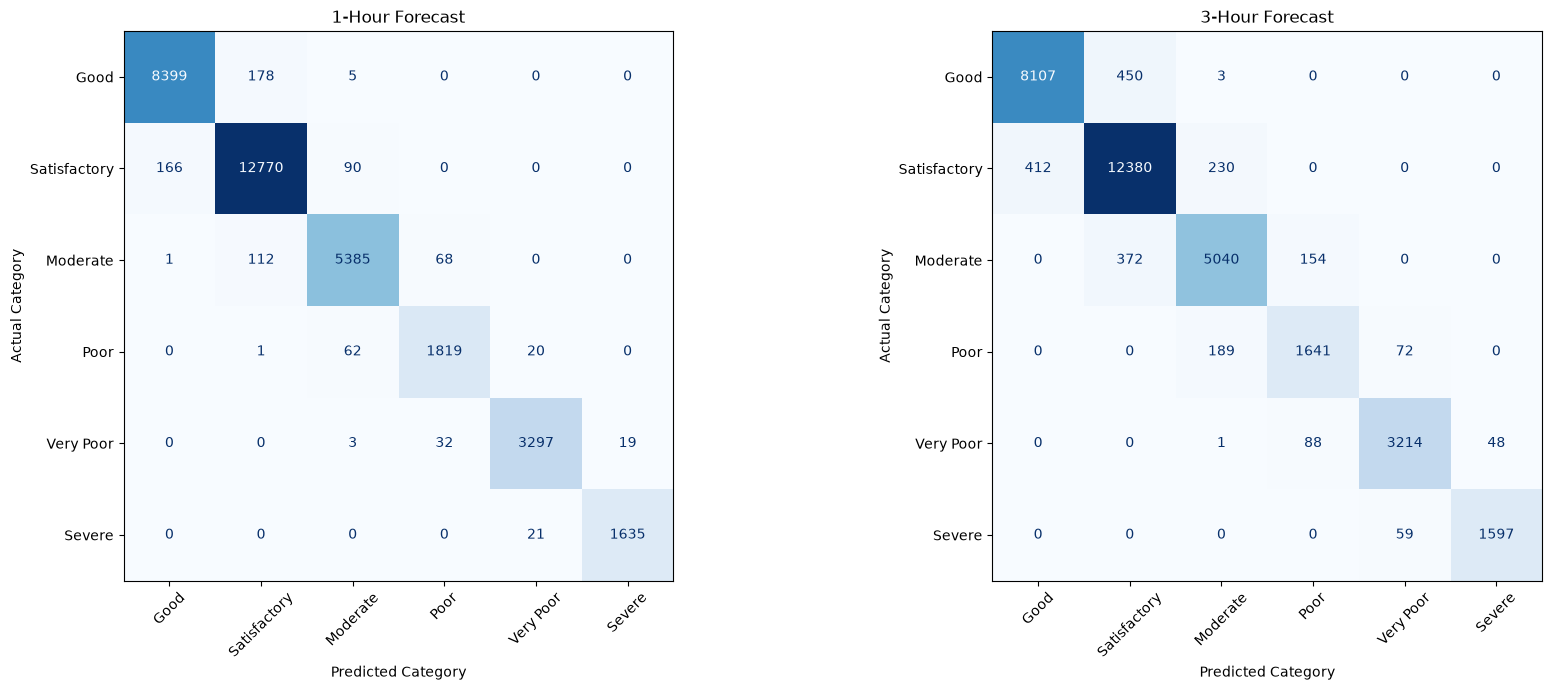

In [51]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

categories = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, horizon, y_true, y_pred in [
    (axes[0], "1-Hour Forecast", y_test_1h, y_pred_1h),
    (axes[1], "3-Hour Forecast", y_test_3h, y_pred_3h)
]:
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=categories
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=categories
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=45,
        colorbar=False,
        values_format="d"
    )

    ax.set_title(horizon)
    ax.set_xlabel("Predicted Category")
    ax.set_ylabel("Actual Category")

plt.tight_layout()
plt.show()

In [53]:
from IPython.display import display as show_table

show_table(cost_df_final.round(4))

,Horizon,Total Cost,Average Cost
0,1-hour,1203,0.0353
1,3-hour,3209,0.0942


In [54]:
import numpy as np
import pandas as pd

categories = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

# Custom cost matrix
cost_matrix = np.array([
    [0, 1, 3, 6, 10, 15],
    [2, 0, 1, 4, 8, 13],
    [4, 2, 0, 1, 5, 10],
    [7, 5, 2, 0, 1, 6],
    [11, 9, 6, 2, 0, 1],
    [16, 14, 11, 7, 2, 0]
])

def calculate_cost_score(y_true, y_pred):
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=categories
    )

    total_cost = np.sum(cm * cost_matrix)
    average_cost = total_cost / np.sum(cm)

    return total_cost, average_cost

cost_results = []

for horizon, y_true, y_pred in [
    ("1-hour", y_test_1h, y_pred_1h),
    ("3-hour", y_test_3h, y_pred_3h)
]:
    total_cost, avg_cost = calculate_cost_score(y_true, y_pred)

    cost_results.append({
        "Horizon": horizon,
        "Total Cost": total_cost,
        "Average Cost": avg_cost
    })

cost_df_final = pd.DataFrame(cost_results)

display(cost_df_final.round(4))

TypeError: 'ConfusionMatrixDisplay' object is not callable

In [55]:
from IPython.display import display

# Restore the display function
globals()["display"] = display

In [56]:
show_table(cost_df_final.round(4))

,Horizon,Total Cost,Average Cost
0,1-hour,1203,0.0353
1,3-hour,3209,0.0942


In [57]:
# Inspect previously created evaluation variables

variables_to_check = [
    "results_df",
    "cost_df",
    "models_1h",
    "models_3h",
    "predictions_1h",
    "predictions_3h"
]

for var in variables_to_check:
    if var in globals():
        obj = globals()[var]
        print(f"\n{var}: Available ({type(obj).__name__})")

        if isinstance(obj, pd.DataFrame):
            print("Shape:", obj.shape)
            print("Columns:", obj.columns.tolist())
            display(obj.head())
        elif isinstance(obj, dict):
            print("Keys:", list(obj.keys()))
    else:
        print(f"\n{var}: Not available")


results_df: Available (DataFrame)
Shape: (12, 7)
Columns: ['Model', 'Horizon', 'Accuracy', 'Precision', 'Recall', 'Macro F1', 'Weighted F1']


,Model,Horizon,Accuracy,Precision,Recall,Macro F1,Weighted F1
0,Logistic Regression,1-hour,0.947892,0.938323,0.955803,0.946041,0.948066
1,Logistic Regression,3-hour,0.906539,0.891787,0.914241,0.901284,0.906728
2,Decision Tree,1-hour,0.968137,0.966068,0.965401,0.965700,0.968148
3,Decision Tree,3-hour,0.902722,0.893580,0.892403,0.892821,0.902816
4,Random Forest,1-hour,0.971100,0.966100,0.971640,0.968784,0.971142



cost_df: Available (DataFrame)
Shape: (6, 3)
Columns: ['Model', '1-hour Average Cost', '3-hour Average Cost']


,Model,1-hour Average Cost,3-hour Average Cost
5,Gradient Boosting,0.034973,0.094224
2,Random Forest,0.044832,0.105823
1,Decision Tree,0.048969,0.146989
0,Logistic Regression,0.088020,0.148604
3,Extra Trees,0.092803,0.149074



models_1h: Available (dict)
Keys: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Extra Trees', 'KNN', 'Gradient Boosting']

models_3h: Available (dict)
Keys: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Extra Trees', 'KNN', 'Gradient Boosting']

predictions_1h: Available (dict)
Keys: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Extra Trees', 'KNN', 'Gradient Boosting']

predictions_3h: Available (dict)
Keys: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Extra Trees', 'KNN', 'Gradient Boosting']


In [58]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

comparison_rows = []

# Previous models: reuse their existing predictions
for horizon, y_true, predictions in [
    ("1-hour", y_test_1h, predictions_1h),
    ("3-hour", y_test_3h, predictions_3h)
]:
    for model_name, y_pred in predictions.items():

        comparison_rows.append({
            "Model": model_name,
            "Horizon": horizon,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Macro F1": f1_score(y_true, y_pred, average="macro"),
            "Weighted F1": f1_score(y_true, y_pred, average="weighted")
        })

# Add our newly trained final models
for horizon, y_true, y_pred in [
    ("1-hour", y_test_1h, y_pred_1h),
    ("3-hour", y_test_3h, y_pred_3h)
]:
    comparison_rows.append({
        "Model": "Final Gradient Boosting",
        "Horizon": horizon,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro"),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted")
    })

comparison_df = pd.DataFrame(comparison_rows)

comparison_df = comparison_df.sort_values(
    ["Horizon", "Macro F1"],
    ascending=[True, False]
).reset_index(drop=True)

show_table(comparison_df.round(4))

,Model,Horizon,Accuracy,Macro F1,Weighted F1
0,Gradient Boosting,1-hour,0.9774,0.9758,0.9774
1,Final Gradient Boosting,1-hour,0.9772,0.9756,0.9772
2,Random Forest,1-hour,0.9711,0.9688,0.9711
3,Decision Tree,1-hour,0.9681,0.9657,0.9681
4,Logistic Regression,1-hour,0.9479,0.9460,0.9481
5,Extra Trees,1-hour,0.9421,0.9354,0.9418
6,KNN,1-hour,0.6020,0.5895,0.5816
7,Gradient Boosting,3-hour,0.9390,0.9337,0.9389
8,Final Gradient Boosting,3-hour,0.9390,0.9337,0.9389
9,Random Forest,3-hour,0.9318,0.9251,0.9319


In [59]:
baseline_results = pd.DataFrame([
    {
        "Horizon": "1-hour",
        "Model": "Persistence",
        "Accuracy": 0.96911834,
        "Macro F1": 0.96724055
    },
    {
        "Horizon": "1-hour",
        "Model": "Final Gradient Boosting",
        "Accuracy": accuracy_score(y_test_1h, y_pred_1h),
        "Macro F1": f1_score(y_test_1h, y_pred_1h, average="macro")
    },
    {
        "Horizon": "3-hour",
        "Model": "Persistence",
        "Accuracy": 0.91869387,
        "Macro F1": 0.91210604
    },
    {
        "Horizon": "3-hour",
        "Model": "Final Gradient Boosting",
        "Accuracy": accuracy_score(y_test_3h, y_pred_3h),
        "Macro F1": f1_score(y_test_3h, y_pred_3h, average="macro")
    }
])

show_table(baseline_results.round(4))

,Horizon,Model,Accuracy,Macro F1
0,1-hour,Persistence,0.9691,0.9672
1,1-hour,Final Gradient Boosting,0.9772,0.9756
2,3-hour,Persistence,0.9187,0.9121
3,3-hour,Final Gradient Boosting,0.9390,0.9337


In [60]:
# Inspect available timestamp-related variables

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        date_cols = [
            col for col in obj.columns
            if any(word in col.lower()
                   for word in ["timestamp", "datetime", "date", "time"])
        ]

        if date_cols:
            print(f"{name}: {date_cols}")

model_df: ['candidate_station']
train_df: ['candidate_station']
test_df: ['candidate_station']
X_train_1h: ['candidate_station']
X_test_1h: ['candidate_station']
X_train_3h: ['candidate_station']
X_test_3h: ['candidate_station']
X_knn_1h: ['candidate_station']
X_knn_3h: ['candidate_station']
tuning_train_df: ['candidate_station']
tuning_val_df: ['candidate_station']
X_tune_train_1h: ['candidate_station']
X_val_1h: ['candidate_station']
X_tune_train_3h: ['candidate_station']
X_val_3h: ['candidate_station']
X_train: ['candidate_station']
X_val: ['candidate_station']


In [61]:
# Inspect the structure of our original training dataframe

print("train_df columns:")
print(train_df.columns.tolist())

print("\nIndex type:")
print(type(train_df.index))

print("\nIndex name:")
print(train_df.index.name)

print("\nIndex sample:")
print(train_df.index[:5])

print("\nFirst 5 rows:")
show_table(train_df.head())

train_df columns:
['observed_at_ist', 'observed_at', 'location_id', 'station_name', 'candidate_station', 'region', 'latitude', 'longitude', 'co', 'no', 'no2', 'nox', 'o3', 'pm10', 'pm25', 'relative_humidity', 'so2', 'temperature', 'wind_direction', 'wind_speed', 'PM25_Missing', 'co_missing', 'no_missing', 'no2_missing', 'nox_missing', 'o3_missing', 'pm10_missing', 'relative_humidity_missing', 'so2_missing', 'temperature_missing', 'wind_direction_missing', 'wind_speed_missing', 'wind_direction_sin', 'wind_direction_cos', 'PM25_next_1h', 'PM25_next_3h', 'available_aqi_pollutants', 'pm25_24h_avg', 'pm25_aqi_category', 'target_1h', 'target_3h', 'hour', 'day', 'day_of_week', 'month', 'is_weekend', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'pm25_lag_1', 'pm25_lag_3', 'pm25_lag_6', 'pm25_lag_12', 'pm25_lag_24', 'pm25_rolling_mean_6h', 'pm25_rolling_mean_12h', 'pm25_rolling_mean_24h', 'pm25_rolling_std_24h']

Index type:
<class 'pandas.RangeIndex'>

Index name:
None

Index sample:
Rang

,observed_at_ist,observed_at,location_id,station_name,candidate_station,region,latitude,longitude,co,no,...,month_cos,pm25_lag_1,pm25_lag_3,pm25_lag_6,pm25_lag_12,pm25_lag_24,pm25_rolling_mean_6h,pm25_rolling_mean_12h,pm25_rolling_mean_24h,pm25_rolling_std_24h
0,2025-02-19 01:00:00+05:30,2025-02-18 19:30:00+00:00,6932,"Alipur, Delhi - DPCC",Alipur,North Delhi,28.815329,77.153010,0.150,5.0,...,0.866025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025-02-19 01:00:00+05:30,2025-02-18 19:30:00+00:00,10486,"Mundka, Delhi - DPCC",Mundka,West Delhi,28.684678,77.076574,0.945,62.6,...,0.866025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2025-02-19 01:00:00+05:30,2025-02-18 19:30:00+00:00,50,"Punjabi Bagh, Delhi - DPCC",Punjabi Bagh,West Delhi,28.674045,77.131023,1.160,31.6,...,0.866025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2025-02-19 01:00:00+05:30,2025-02-18 19:30:00+00:00,6358,"Mandir Marg, New Delhi - DPCC",Mandir Marg,Central Delhi,28.636429,77.201067,1.990,98.0,...,0.866025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2025-02-19 01:00:00+05:30,2025-02-18 19:30:00+00:00,6356,"Pusa, Delhi - DPCC",Pusa,Central Delhi,28.639645,77.146262,0.970,138.0,...,0.866025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [62]:
# Check whether training feature indices align with train_df

print("train_df shape:", train_df.shape)
print("X_train_1h shape:", X_train_1h.shape)
print("X_train_3h shape:", X_train_3h.shape)

print("\nIndex alignment:")
print(
    "1-hour:",
    X_train_1h.index.equals(y_train_1h.index)
)
print(
    "3-hour:",
    X_train_3h.index.equals(y_train_3h.index)
)

print("\nCan map 1-hour indices to timestamps:",
      X_train_1h.index.isin(train_df.index).all())

print("Can map 3-hour indices to timestamps:",
      X_train_3h.index.isin(train_df.index).all())

print("\nTimestamp sample:")
show_table(
    train_df.loc[
        X_train_1h.index[:5],
        ["observed_at_ist", "candidate_station"]
    ]
)

train_df shape: (158130, 59)
X_train_1h shape: (142895, 45)
X_train_3h shape: (142921, 45)

Index alignment:
1-hour: True
3-hour: True

Can map 1-hour indices to timestamps: True
Can map 3-hour indices to timestamps: True

Timestamp sample:


,observed_at_ist,candidate_station
180,2025-02-19 15:00:00+05:30,Dwarka
181,2025-02-19 15:00:00+05:30,RK Puram
182,2025-02-19 15:00:00+05:30,Alipur
183,2025-02-19 15:00:00+05:30,Pusa
185,2025-02-19 15:00:00+05:30,Mandir Marg


In [63]:
import numpy as np
import pandas as pd
import time

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import accuracy_score, f1_score

# Map every training sample to its timestamp
timestamps_1h = train_df.loc[
    X_train_1h.index, "observed_at_ist"
]

# Sort unique timestamps chronologically
unique_times_1h = np.sort(timestamps_1h.unique())

# 3-fold expanding-window CV, with 3-hour purge
tscv_1h = TimeSeriesSplit(
    n_splits=3,
    gap=3
)

config_1h = {
    "n_estimators": 150,
    "learning_rate": 0.05,
    "max_depth": 3,
    "min_samples_leaf": 2,
    "random_state": 42
}

cv_results_1h = []

for fold, (train_time_idx, val_time_idx) in enumerate(
    tscv_1h.split(unique_times_1h), start=1
):
    fold_train_times = unique_times_1h[train_time_idx]
    fold_val_times = unique_times_1h[val_time_idx]

    train_mask = timestamps_1h.isin(fold_train_times)
    val_mask = timestamps_1h.isin(fold_val_times)

    X_fold_train = X_train_1h.loc[train_mask]
    y_fold_train = y_train_1h.loc[train_mask]

    X_fold_val = X_train_1h.loc[val_mask]
    y_fold_val = y_train_1h.loc[val_mask]

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", GradientBoostingClassifier(**config_1h))
    ])

    print(f"\nTraining 1-hour Fold {fold}...")
    print("Training rows:", len(X_fold_train))
    print("Validation rows:", len(X_fold_val))

    start = time.time()

    pipeline.fit(X_fold_train, y_fold_train)
    predictions = pipeline.predict(X_fold_val)

    elapsed = (time.time() - start) / 60

    cv_results_1h.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y_fold_val, predictions),
        "Macro F1": f1_score(
            y_fold_val, predictions, average="macro"
        ),
        "Weighted F1": f1_score(
            y_fold_val, predictions, average="weighted"
        ),
        "Training Rows": len(X_fold_train),
        "Validation Rows": len(X_fold_val),
        "Time (minutes)": round(elapsed, 2)
    })

    print(f"Fold {fold} completed in {elapsed:.2f} minutes.")

cv_1h_df = pd.DataFrame(cv_results_1h)

print("\n1-HOUR CROSS-VALIDATION RESULTS")
show_table(cv_1h_df.round(4))

print("\nAVERAGE CV PERFORMANCE")
show_table(
    cv_1h_df[["Accuracy", "Macro F1", "Weighted F1"]]
    .mean()
    .to_frame("Mean Score")
    .round(4)
)


Training 1-hour Fold 1...
Training rows: 35544
Validation rows: 35295
Fold 1 completed in 4.60 minutes.

Training 1-hour Fold 2...
Training rows: 70833
Validation rows: 36461
Fold 2 completed in 9.86 minutes.

Training 1-hour Fold 3...
Training rows: 107296
Validation rows: 35562
Fold 3 completed in 19.54 minutes.

1-HOUR CROSS-VALIDATION RESULTS


,Fold,Accuracy,Macro F1,Weighted F1,Training Rows,Validation Rows,Time (minutes)
0,1,0.9763,0.9370,0.9761,35544,35295,4.60
1,2,0.9735,0.9650,0.9735,70833,36461,9.86
2,3,0.9711,0.9624,0.9711,107296,35562,19.54



AVERAGE CV PERFORMANCE


,Mean Score
Accuracy,0.9736
Macro F1,0.9548
Weighted F1,0.9736
